# Sorting Race Results with Two Algorithms
## Assignment 1 — Analysis of Algorithms

**Objective:** Implement Merge Sort and stable LSD Radix Sort, verify their correctness, and compare their performance using execution time and operation counts.

The experiments use reproducible datasets of non-negative integers representing race finish times. Both algorithms must produce the same sorted result.


In [1]:
import random
import time
import statistics
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible experiment settings
SEED = 20261025
MAX_VALUE = 9_999_999
DATASET_SIZES = [1_000, 5_000, 10_000, 50_000, 100_000]
NUM_TRIALS = 3

random.seed(SEED)

print("Libraries imported successfully.")
print("Dataset sizes:", DATASET_SIZES)
print("Random seed:", SEED)


Libraries imported successfully.
Dataset sizes: [1000, 5000, 10000, 50000, 100000]
Random seed: 20261025


In [2]:

def merge_sort(arr):
    """
    Sort a list using Merge Sort.

    Returns:
        sorted_arr: sorted copy of the input list
        stats: operation counts
    """
    stats = {
        "comparisons": 0,
        "copies": 0
    }

    def sort(items):
        if len(items) <= 1:
            return items.copy()

        mid = len(items) // 2
        left = sort(items[:mid])
        right = sort(items[mid:])

        merged = []
        i = 0
        j = 0

        while i < len(left) and j < len(right):
            stats["comparisons"] += 1

            if left[i] <= right[j]:
                merged.append(left[i])
                i += 1
            else:
                merged.append(right[j])
                j += 1

            stats["copies"] += 1

        while i < len(left):
            merged.append(left[i])
            i += 1
            stats["copies"] += 1

        while j < len(right):
            merged.append(right[j])
            j += 1
            stats["copies"] += 1

        return merged

    return sort(arr), stats


In [3]:

test_cases = [
    [],
    [5],
    [3, 1, 2],
    [4, 2, 2, 4, 1],
    [1, 2, 3, 4, 5],
    [5, 4, 3, 2, 1],
    [10, 1, 100, 0, 9_999_999],
    [100, 10, 1, 1_000, 10]
]

for index, test_data in enumerate(test_cases, start=1):
    result, stats = merge_sort(test_data)
    assert result == sorted(test_data), f"Test {index} failed"
    assert test_data == test_data.copy(), f"Input changed in test {index}"
    print(f"Test {index}: PASS")

print(f"\nAll {len(test_cases)} Merge Sort tests passed.")


Test 1: PASS
Test 2: PASS
Test 3: PASS
Test 4: PASS
Test 5: PASS
Test 6: PASS
Test 7: PASS
Test 8: PASS

All 8 Merge Sort tests passed.


In [4]:

def lsd_radix_sort(arr):
    """
    Stable LSD Radix Sort for non-negative integers.

    Returns:
        sorted_arr: sorted copy of the input list
        stats: operation counts
    """
    if any(value < 0 for value in arr):
        raise ValueError("LSD Radix Sort supports non-negative integers only.")

    result = arr.copy()

    stats = {
        "digit_inspections": 0,
        "placements": 0
    }

    if not result:
        return result, stats

    max_value = max(result)
    exp = 1
    base = 10

    # Process every decimal digit, including leading zero digits.
    while exp <= 10**6:
        output = [0] * len(result)
        count = [0] * base

        # Count occurrences of each digit.
        for value in result:
            digit = (value // exp) % base
            count[digit] += 1
            stats["digit_inspections"] += 1

        # Convert counts into cumulative positions.
        for i in range(1, base):
            count[i] += count[i - 1]

        # Traverse backwards to preserve stability.
        for i in range(len(result) - 1, -1, -1):
            value = result[i]
            digit = (value // exp) % base
            count[digit] -= 1
            output[count[digit]] = value
            stats["placements"] += 1

        result = output
        exp *= base

    return result, stats


In [5]:

for index, test_data in enumerate(test_cases, start=1):
    result, stats = lsd_radix_sort(test_data)
    assert result == sorted(test_data), f"Test {index} failed"
    assert test_data == test_data.copy(), f"Input changed in test {index}"
    print(f"Test {index}: PASS")

print(f"\nAll {len(test_cases)} LSD Radix Sort tests passed.")

# Verify that negative numbers are rejected.
try:
    lsd_radix_sort([3, -1, 2])
    raise AssertionError("Negative-number test failed")
except ValueError:
    print("Negative-number validation: PASS")


Test 1: PASS
Test 2: PASS
Test 3: PASS
Test 4: PASS
Test 5: PASS
Test 6: PASS
Test 7: PASS
Test 8: PASS

All 8 LSD Radix Sort tests passed.
Negative-number validation: PASS


In [6]:
def generate_datasets():
    """Generate reproducible datasets for all experiment sizes."""
    rng = random.Random(SEED)
    datasets = {}

    for size in DATASET_SIZES:
        datasets[size] = [
            rng.randint(0, MAX_VALUE)
            for _ in range(size)
        ]

    return datasets


datasets = generate_datasets()

print("Datasets generated successfully.")

for size, data in datasets.items():
    print(
        f"n={size:>6}: "
        f"min={min(data):>7}, "
        f"max={max(data):>7}, "
        f"records={len(data)}"
    )


Datasets generated successfully.
n=  1000: min=   4832, max=9991785, records=1000
n=  5000: min=   1160, max=9996362, records=5000
n= 10000: min=    149, max=9998895, records=10000
n= 50000: min=    391, max=9999991, records=50000
n=100000: min=     55, max=9999912, records=100000


In [7]:

def benchmark_algorithm(sort_function, data, expected):
    """
    Measure sorting time over repeated runs.
    Data copying and correctness checks are excluded from timing.
    """
    elapsed_times = []
    operation_stats = None

    for _ in range(3):
        input_data = data.copy()

        start = time.perf_counter()
        result, stats = sort_function(input_data)
        end = time.perf_counter()

        assert result == expected, "Sorting result is incorrect!"

        elapsed_times.append(end - start)
        operation_stats = stats

    median_ms = statistics.median(elapsed_times) * 1000

    return median_ms, operation_stats


results = []

for size, data in datasets.items():
    expected = sorted(data)

    for algorithm_name, sort_function in [
        ("Merge Sort", merge_sort),
        ("LSD Radix Sort", lsd_radix_sort)
    ]:
        median_ms, stats = benchmark_algorithm(
            sort_function,
            data,
            expected
        )

        row = {
            "Input Size": size,
            "Algorithm": algorithm_name,
            "Median Time (ms)": round(median_ms, 4)
        }
        row.update(stats)
        results.append(row)

        print(
            f"n={size:>6} | "
            f"{algorithm_name:<14} | "
            f"{median_ms:>10.4f} ms"
        )

results_df = pd.DataFrame(results)

print("\nAll benchmark runs completed successfully.")


n=  1000 | Merge Sort     |     2.3267 ms
n=  1000 | LSD Radix Sort |     1.9764 ms
n=  5000 | Merge Sort     |    46.0119 ms
n=  5000 | LSD Radix Sort |    23.0984 ms
n= 10000 | Merge Sort     |    78.0762 ms
n= 10000 | LSD Radix Sort |    46.0919 ms
n= 50000 | Merge Sort     |   443.0405 ms
n= 50000 | LSD Radix Sort |   236.1207 ms
n=100000 | Merge Sort     |   949.6000 ms
n=100000 | LSD Radix Sort |   471.6367 ms

All benchmark runs completed successfully.


In [8]:
display(results_df)

,Input Size,Algorithm,Median Time (ms),comparisons,copies,digit_inspections,placements
0,1000,Merge Sort,2.3267,8698.0,9976.0,NaN,NaN
1,1000,LSD Radix Sort,1.9764,NaN,NaN,7000.0,7000.0
2,5000,Merge Sort,46.0119,55240.0,61808.0,NaN,NaN
3,5000,LSD Radix Sort,23.0984,NaN,NaN,35000.0,35000.0
4,10000,Merge Sort,78.0762,120360.0,133616.0,NaN,NaN
5,10000,LSD Radix Sort,46.0919,NaN,NaN,70000.0,70000.0
6,50000,Merge Sort,443.0405,718271.0,784464.0,NaN,NaN
7,50000,LSD Radix Sort,236.1207,NaN,NaN,350000.0,350000.0
8,100000,Merge Sort,949.6000,1536235.0,1668928.0,NaN,NaN
9,100000,LSD Radix Sort,471.6367,NaN,NaN,700000.0,700000.0


In [9]:

# Table comparing execution times
time_table = results_df.pivot(
    index="Input Size",
    columns="Algorithm",
    values="Median Time (ms)"
).reset_index()

display(time_table)

# Separate operation-count tables
merge_table = results_df[
    results_df["Algorithm"] == "Merge Sort"
].drop(columns=["Algorithm", "Median Time (ms)"]).reset_index(drop=True)

radix_table = results_df[
    results_df["Algorithm"] == "LSD Radix Sort"
].drop(columns=["Algorithm", "Median Time (ms)"]).reset_index(drop=True)

print("Merge Sort operation counts:")
display(merge_table)

print("LSD Radix Sort operation counts:")
display(radix_table)


Algorithm,Input Size,LSD Radix Sort,Merge Sort
0,1000,1.9764,2.3267
1,5000,23.0984,46.0119
2,10000,46.0919,78.0762
3,50000,236.1207,443.0405
4,100000,471.6367,949.6000


Merge Sort operation counts:


,Input Size,comparisons,copies,digit_inspections,placements
0,1000,8698.0,9976.0,NaN,NaN
1,5000,55240.0,61808.0,NaN,NaN
2,10000,120360.0,133616.0,NaN,NaN
3,50000,718271.0,784464.0,NaN,NaN
4,100000,1536235.0,1668928.0,NaN,NaN


LSD Radix Sort operation counts:


,Input Size,comparisons,copies,digit_inspections,placements
0,1000,NaN,NaN,7000.0,7000.0
1,5000,NaN,NaN,35000.0,35000.0
2,10000,NaN,NaN,70000.0,70000.0
3,50000,NaN,NaN,350000.0,350000.0
4,100000,NaN,NaN,700000.0,700000.0


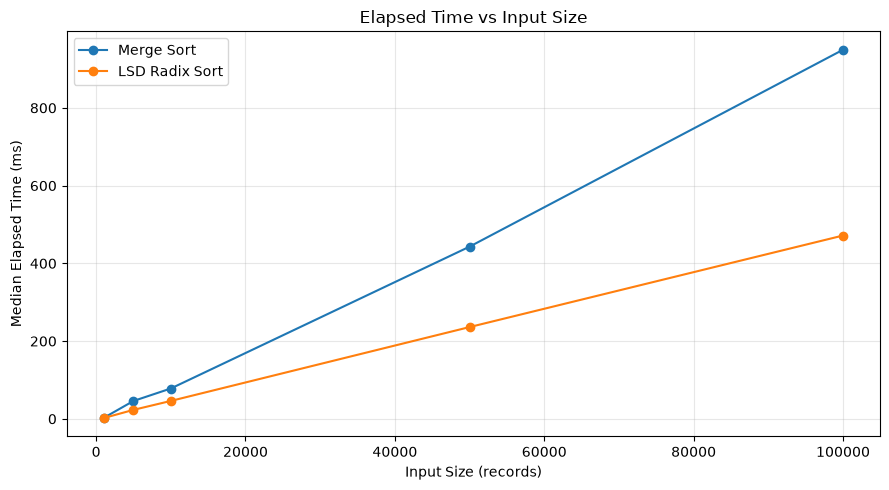

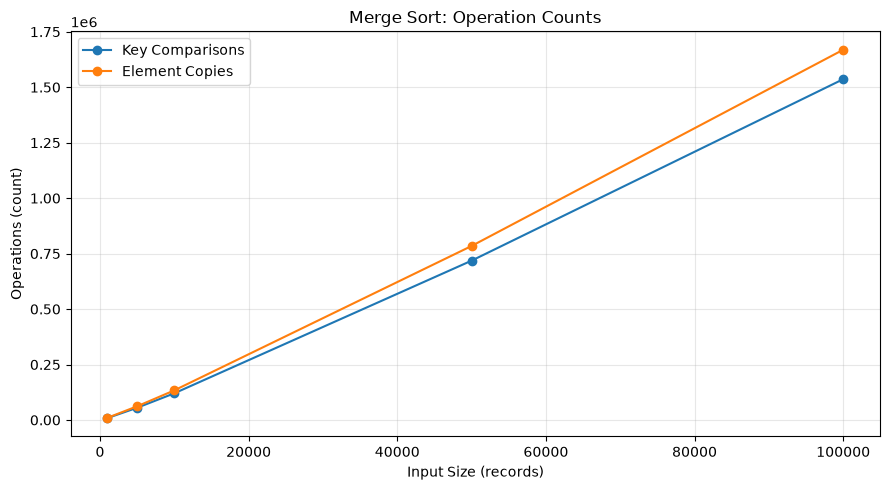

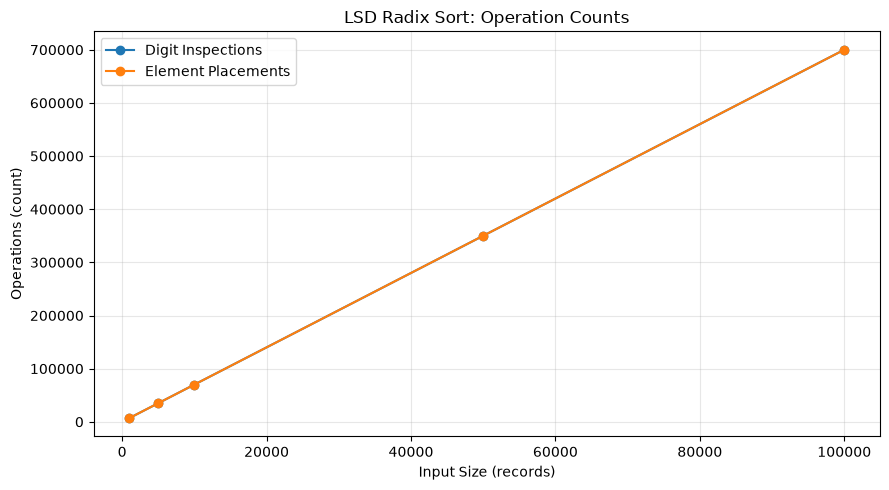

All three charts saved successfully.


In [10]:

# Chart 1: Execution time comparison
plt.figure(figsize=(9, 5))

plt.plot(
    time_table["Input Size"],
    time_table["Merge Sort"],
    marker="o",
    label="Merge Sort"
)

plt.plot(
    time_table["Input Size"],
    time_table["LSD Radix Sort"],
    marker="o",
    label="LSD Radix Sort"
)

plt.title("Elapsed Time vs Input Size")
plt.xlabel("Input Size (records)")
plt.ylabel("Median Elapsed Time (ms)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("elapsed_time_comparison.png", dpi=200)
plt.show()


# Chart 2: Merge Sort operation counts
plt.figure(figsize=(9, 5))

plt.plot(
    merge_table["Input Size"],
    merge_table["comparisons"],
    marker="o",
    label="Key Comparisons"
)

plt.plot(
    merge_table["Input Size"],
    merge_table["copies"],
    marker="o",
    label="Element Copies"
)

plt.title("Merge Sort: Operation Counts")
plt.xlabel("Input Size (records)")
plt.ylabel("Operations (count)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("merge_sort_operations.png", dpi=200)
plt.show()


# Chart 3: LSD Radix Sort operation counts
plt.figure(figsize=(9, 5))

plt.plot(
    radix_table["Input Size"],
    radix_table["digit_inspections"],
    marker="o",
    label="Digit Inspections"
)

plt.plot(
    radix_table["Input Size"],
    radix_table["placements"],
    marker="o",
    label="Element Placements"
)

plt.title("LSD Radix Sort: Operation Counts")
plt.xlabel("Input Size (records)")
plt.ylabel("Operations (count)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("radix_sort_operations.png", dpi=200)
plt.show()

print("All three charts saved successfully.")


In [11]:

# Save detailed benchmark results
results_df.to_csv("sorting_results.csv", index=False)

# Save the execution-time comparison table
time_table.to_csv("sorting_time_summary.csv", index=False)

# Save operation-count tables
merge_table.to_csv("merge_sort_operations.csv", index=False)
radix_table.to_csv("radix_sort_operations.csv", index=False)

print("Results exported successfully:")
print("- sorting_results.csv")
print("- sorting_time_summary.csv")
print("- merge_sort_operations.csv")
print("- radix_sort_operations.csv")
print("- elapsed_time_comparison.png")
print("- merge_sort_operations.png")
print("- radix_sort_operations.png")


Results exported successfully:
- sorting_results.csv
- sorting_time_summary.csv
- merge_sort_operations.csv
- radix_sort_operations.csv
- elapsed_time_comparison.png
- merge_sort_operations.png
- radix_sort_operations.png


## Theoretical Complexity Analysis

### Merge Sort

Merge Sort recursively divides the input into two halves and merges the sorted halves. Its time complexity is O(n log n) in the best, average, and worst cases. Its auxiliary space complexity is O(n) because additional arrays are used during merging.

### LSD Radix Sort

LSD Radix Sort processes the digits of each number from least significant to most significant. For n input values, d digit passes, and a base b, its time complexity is O(d(n + b)). Its auxiliary space complexity is O(n + b).

In this experiment, the input values are non-negative integers no greater than 9,999,999. Therefore, the algorithm performs seven decimal-digit passes (d = 7) with base b = 10. Since d and b are fixed, the time complexity is O(n) for this bounded input domain.

### Comparison

Merge Sort has O(n log n) time complexity and is applicable to general comparable values. LSD Radix Sort can achieve linear time for fixed-length integer keys, but it requires additional memory and depends on the representation and range of the keys.


In [12]:

summary = time_table.copy()

summary["Speedup (Merge / Radix)"] = (
    summary["Merge Sort"] / summary["LSD Radix Sort"]
).round(2)

display(summary)

print("\nFinal comparison at n = 100,000:")
last = summary.iloc[-1]
print(f"Merge Sort: {last['Merge Sort']:.4f} ms")
print(f"LSD Radix Sort: {last['LSD Radix Sort']:.4f} ms")
print(f"Speedup: {last['Speedup (Merge / Radix)']:.2f}x")


Algorithm,Input Size,LSD Radix Sort,Merge Sort,Speedup (Merge / Radix)
0,1000,1.9764,2.3267,1.18
1,5000,23.0984,46.0119,1.99
2,10000,46.0919,78.0762,1.69
3,50000,236.1207,443.0405,1.88
4,100000,471.6367,949.6000,2.01



Final comparison at n = 100,000:
Merge Sort: 949.6000 ms
LSD Radix Sort: 471.6367 ms
Speedup: 2.01x


In [13]:

def verify_algorithm(sort_function, test_data):
    original = test_data.copy()
    result, stats = sort_function(test_data)

    # Check that the output is in ascending order.
    is_sorted = all(
        result[i] <= result[i + 1]
        for i in range(len(result) - 1)
    )

    # Check that no values were lost, added, or changed.
    preserves_values = (
        len(result) == len(original)
        and sorted(result) == sorted(original)
    )

    # Check that the original input remains unchanged.
    input_preserved = test_data == original

    assert is_sorted, "Output is not sorted."
    assert preserves_values, "Input values were not preserved."
    assert input_preserved, "Original input was modified."

    return {
        "sorted": is_sorted,
        "same_values": preserves_values,
        "input_unchanged": input_preserved
    }


for algorithm_name, algorithm in [
    ("Merge Sort", merge_sort),
    ("LSD Radix Sort", lsd_radix_sort)
]:
    print(f"\n{algorithm_name}")

    for i, test_data in enumerate(test_cases, start=1):
        checks = verify_algorithm(algorithm, test_data)
        print(f"Test {i}: PASS — {checks}")

print("\nAll correctness checks passed.")



Merge Sort
Test 1: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}
Test 2: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}
Test 3: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}
Test 4: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}
Test 5: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}
Test 6: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}
Test 7: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}
Test 8: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}

LSD Radix Sort
Test 1: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}
Test 2: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}
Test 3: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}
Test 4: PASS — {'sorted': True, 'same_values': True, 'input_unchanged': True}
Test 5: PASS — {'sorted': True, 'sam